# 03 - Naming the clusters

Starting from the 15 Leiden clusters (resolution 0.5) from `02_clustering.ipynb`, I name each cluster from its marker genes, look at anything that doesn't fit, and check the names against CellTypist.

**Data** 
- GSE150728 (Wilk et al. 2020, *Nature Medicine*), PBMCs from COVID-19 patients and healthy donors.

**Input**
- `results/clustering/clustered.h5ad`

**Outputs**
- `results/annotation/annotated.h5ad`: same cells with a `cell_type` column
- `results/annotation/cell_counts_per_sample.csv`: cells of each type in each sample

CellTypist isn't in the base environment, so I installed it once with `pip install celltypist`.

## Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)   # celltypist uses a deprecated scanpy attribute on import
    import celltypist
    from celltypist import models

pd.set_option("display.max_colwidth", None)   # show full gene lists in tables

anndata.settings.allow_write_nullable_strings = True
RESULTS = "../results"

adata = sc.read_h5ad(f"{RESULTS}/clustering/clustered.h5ad")
adata

AnnData object with n_obs × n_vars = 46431 × 40448
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition', 'doublet_score', 'predicted_doublet', 'leiden_0.5', 'leiden_1.0'
    var: 'gene_name', 'mt', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'condition_colors', 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'leiden_1.0', 'leiden_1.0_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_uncorrected'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## 1. Marker genes per cluster

Each cluster is compared with all the other cells (Wilcoxon test) and genes are ranked by how much higher they are in that cluster. This treats every cell as a separate data point, which is fine for naming clusters but not for comparing COVID with healthy.

In [2]:
sc.tl.rank_genes_groups(adata, groupby="leiden_0.5", method="wilcoxon", use_raw=False)

markers = sc.get.rank_genes_groups_df(adata, group=None)
markers["gene"] = markers["names"].map(adata.var["gene_name"])   # Ensembl ID -> gene name

top = markers.groupby("group", observed=True).head(10)
top.groupby("group", observed=True)["gene"].apply(", ".join).rename_axis("cluster").to_frame("top 10 genes")

,top 10 genes
cluster,
0,"VCAN, S100A9, LYZ, FCN1, S100A8, CTSS, PSAP, FTL, CYBB, APLP2"
1,"PSAP, FCGR3A, LST1, COTL1, CSF1R, TNFRSF1B, AIF1, LYN, SAT1, FTL"
2,"TUBB1, CAVIN2, NRGN, PRKAR2B, F13A1, ITGB3, VCL, PPBP, RUFY1, H2AC6"
3,"HLA-DRA, CD74, HLA-DPA1, HLA-DRB1, HLA-DPB1, CST3, SAMHD1, HLA-DQA1, HLA-DQB1, HLA-DMA"
4,"IRF8, UGCG, TCF4, CCDC50, ITM2C, APP, CD74, SERPINF1, LILRA4, MPEG1"
5,"CCL5, SYNE1, PRF1, GNLY, SYNE2, ARL4C, GZMA, KLRD1, GZMH, GZMB"
6,"MS4A1, CD74, HLA-DRA, IGHM, BANK1, CD79A, HLA-DPB1, HLA-DRB1, HLA-DPA1, RALGPS2"
7,"IL7R, RPS6, TCF7, TPT1, LTB, RPL13, RPS12, RPS14, EEF1A1, RPLP2"
8,"HBB, HBA2, HBA1, SLC25A37, ALAS2, SNCA, BNIP3L, SLC4A1, SLC25A39, HBD"


Most clusters can be named from these: CD14 monocytes (0: VCAN, S100A8/9, LYZ), CD16 monocytes (1: FCGR3A), platelets (2: TUBB1, ITGB3), dendritic cells (3: HLA-DR genes), pDCs (4: IRF8, TCF4), NK and cytotoxic T cells together (5: PRF1, GNLY, GZMA), B cells (6: MS4A1), CD4 T cells (7: IL7R, TCF7), red cells (8: HBB), dividing cells (9: MKI67), plasmablasts (10: JCHAIN, MZB1), neutrophils (12: FCGR3B, CXCR2), progenitors (13: CDK6, GATA2, MYB) and developing neutrophils (14: CEACAM8, BPI).

The plasmablast cluster also has protein-folding genes (XBP1, HSPA5) near the top, likely linked to high antibody production. Neutrophils are normally removed by Ficoll, so finding them is unusual. Cluster 14 (CEACAM8, BPI, but not FCGR3B or CXCR2) matches the "developing neutrophils" described by Wilk et al. in severe COVID, while cluster 12 expresses the canonical neutrophil markers FCGR3B and CXCR2.

Cluster 11 stands out: its top genes (XACT, KCNQ1OT1, HELLPAR) are long non-coding RNAs that mostly stay in the nucleus, which doesn't match a known blood cell type.

## 2. A closer look at cluster 11

QC numbers per cluster, to see whether cluster 11 looks like low-quality cells. The median doublet score is in here too, to check whether any whole cluster looks like doublets.

In [3]:
qc_by_cluster = adata.obs.groupby("leiden_0.5", observed=True).agg(
    n_cells=("total_counts", "size"),
    median_umis=("total_counts", "median"),
    median_genes=("n_genes_by_counts", "median"),
    median_pct_mt=("pct_counts_mt", "median"),
    median_doublet=("doublet_score", "median"),
    pct_covid=("condition", lambda x: round((x == "COVID").mean() * 100)),
).rename_axis("cluster").round(2)
qc_by_cluster

,n_cells,median_umis,median_genes,median_pct_mt,median_doublet,pct_covid
cluster,,,,,,
0,9796,2372.5,1352.0,6.83,0.05,79
1,1669,2649.0,1494.0,6.43,0.03,44
2,594,1693.0,995.5,7.24,0.07,88
3,481,3617.0,1881.0,7.51,0.05,53
4,228,2292.0,1405.5,5.91,0.08,41
5,13093,1538.0,1010.0,7.30,0.05,41
6,3484,1524.0,962.0,9.79,0.03,46
7,11918,1494.0,951.0,7.71,0.05,48
8,282,1422.5,734.0,4.86,0.08,63


Cluster 11 has a median of about 1% mitochondrial reads, compared with 6-10% in every other cluster, and almost every UMI comes from a different gene (1,221 genes from 1,382 UMIs). Since mitochondria are in the cytoplasm, nuclear RNA with very little mitochondrial RNA suggests these barcodes captured nuclei that lost their cytoplasm rather than intact cells.

No cluster has a high median doublet score (all 0.08 or below), so there is no obvious doublet cluster. The last column (pct_covid) shows large differences in the COVID share of each cluster, e.g. 96% for plasmablasts and 95% for developing neutrophils.

## 3. The authors' genes-per-UMI filter

The authors removed cells with more than 75 genes per 100 UMIs to filter out likely multiplets, a filter I skipped during QC. Cluster 11 sits at 88 per 100, so this filter would likely catch it. Here I check what else it would remove in this data. A cell fails the filter if its genes-per-UMI ratio is above 0.75.

Cells failing (genes per UMI > 0.75): 1460


,fail,pass
cluster,,
0,77,9719
1,5,1664
2,18,576
3,2,479
4,8,220
5,541,12552
6,57,3427
7,259,11659
8,13,269


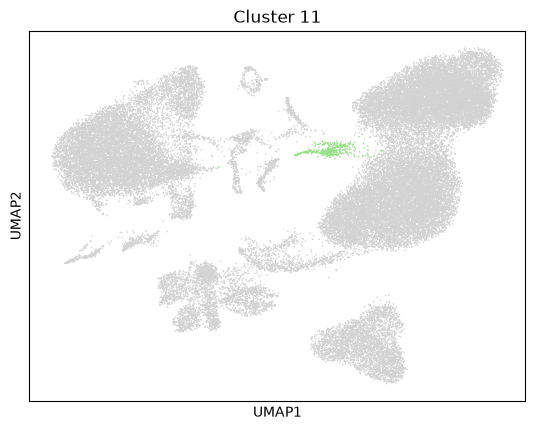

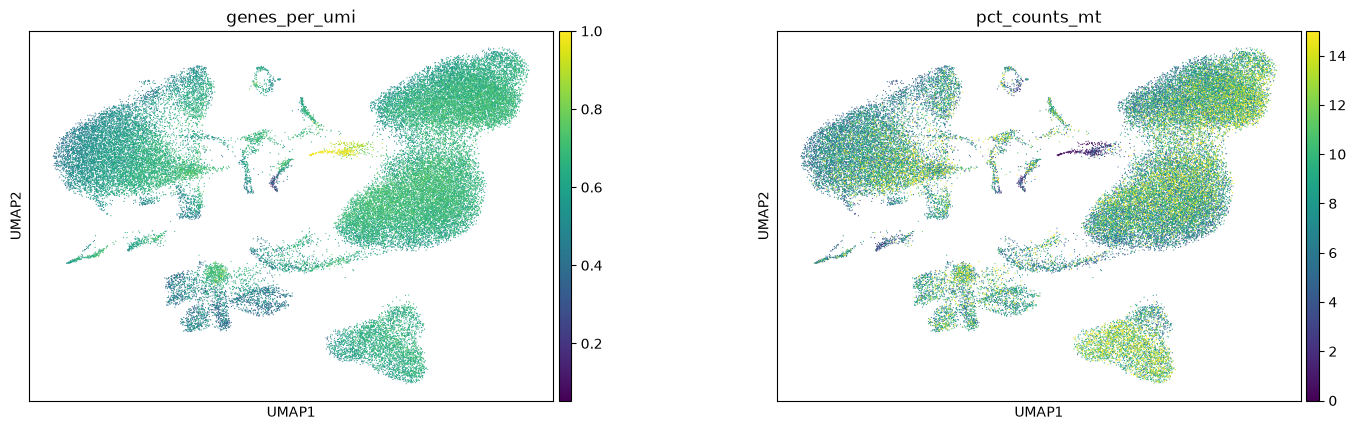

In [4]:
adata.obs["genes_per_umi"] = adata.obs["n_genes_by_counts"] / adata.obs["total_counts"]
high_complexity = adata.obs["genes_per_umi"] > 0.75
status = high_complexity.map({False: "pass", True: "fail"})

print("Cells failing (genes per UMI > 0.75):", high_complexity.sum())
fail_table = pd.crosstab(adata.obs["leiden_0.5"], status).rename_axis(index="cluster", columns=None)
display(fail_table[fail_table["fail"] > 0])

sc.pl.umap(adata, color="leiden_0.5", groups=["11"], title="Cluster 11", legend_loc=None, size=5)
sc.pl.umap(adata, color=["genes_per_umi", "pct_counts_mt"], vmax=[1, 15], wspace=0.3)

362 of the 386 cells in cluster 11 fail, but so do about 1,100 cells in other clusters, mostly in clusters 5 (NK/CD8 T) and 7 (CD4 T). On the UMAPs, cluster 11 is the small strand in the middle, which stands out as the highest genes-per-UMI and lowest mitochondrial % region.

Small cells with few UMIs tend to have a higher genes-per-UMI ratio, and my UMI counts are about 10% lower than the authors', so the same cutoff probably removes more cells here than it did for them. Comparing the failing and passing cells in clusters 5 and 7:

In [5]:
lymph = adata.obs["leiden_0.5"].isin(["5", "7"])
(adata.obs[lymph]
    .groupby(status[lymph].rename("genes_per_umi filter"))[["total_counts", "pct_counts_mt"]]
    .median()
    .rename(columns={"total_counts": "median UMIs", "pct_counts_mt": "median % MT"}))

,median UMIs,median % MT
genes_per_umi filter,,
fail,1021.5,4.809619
pass,1541.0,7.616222


The failing lymphocytes have fewer UMIs, but their median mitochondrial % (4.8) is well above cluster 11's 1%, so most of them look like small, intact cells. Instead of the plain cutoff, I flag cells with both high complexity and very low mitochondrial RNA (under 2%, between cluster 11 and the normal clusters).

In [6]:
artifact = (adata.obs["genes_per_umi"] > 0.75) & (adata.obs["pct_counts_mt"] < 2)

print("Artifact-like cells:", artifact.sum())
(adata.obs.loc[artifact, "leiden_0.5"].value_counts()
    .loc[lambda s: s > 0]
    .rename_axis("cluster")
    .to_frame("artifact-like cells"))

Artifact-like cells: 279


,artifact-like cells
cluster,
11,253
5,12
10,8
7,3
12,2
14,1


253 of these 279 cells are in cluster 11 and only 26 are spread across other clusters, so this picks out the artifact without taking the small lymphocytes with it.

## 4. Remove the artifact cells and name the clusters

The rule above flags 253 of the 386 cells in cluster 11. The other 133 miss one of the two cutoffs: 24 are at or below 0.75 genes per UMI, and 109 are above it but have 2% MT or more. They have the same expression profile as the rest of the cluster, which is why they clustered together, so I remove all of cluster 11 plus the 26 flagged cells in other clusters, 412 cells in total. That's under 1% of cells, so the existing UMAP and clusters are still fine to use.

Removed: 412 | cells left: 46019


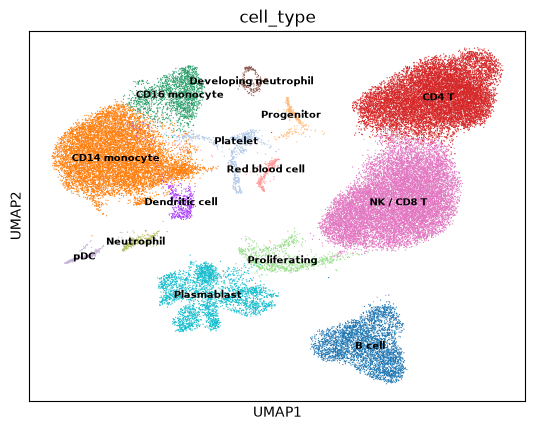

,cells
cell type,
NK / CD8 T,13081
CD4 T,11915
CD14 monocyte,9796
B cell,3484
Plasmablast,2928
CD16 monocyte,1669
Proliferating,852
Platelet,594
Dendritic cell,481


In [7]:
remove = artifact | (adata.obs["leiden_0.5"] == "11")
adata = adata[~remove].copy()
print("Removed:", remove.sum(), "| cells left:", adata.n_obs)

names = {
    "0":  "CD14 monocyte",
    "1":  "CD16 monocyte",
    "2":  "Platelet",
    "3":  "Dendritic cell",
    "4":  "pDC",
    "5":  "NK / CD8 T",
    "6":  "B cell",
    "7":  "CD4 T",
    "8":  "Red blood cell",
    "9":  "Proliferating",
    "10": "Plasmablast",
    "12": "Neutrophil",
    "13": "Progenitor",
    "14": "Developing neutrophil",
}
adata.obs["cell_type"] = adata.obs["leiden_0.5"].astype(str).map(names).astype("category")
assert adata.obs["cell_type"].notna().all()

sc.pl.umap(adata, color="cell_type", legend_loc="on data", legend_fontsize=7, size=3)
adata.obs["cell_type"].value_counts().rename_axis("cell type").to_frame("cells")

## 5. Checking the names with CellTypist

CellTypist is a classifier trained on a large set of hand-labeled immune cells, so it gives an independent label for each cell. With majority voting, each `leiden_1.0` cluster gets its most common label, which smooths out noisy single-cell calls. It needs gene names instead of Ensembl IDs, so I give it a copy with gene names as the index.

In [8]:
models.download_models(model=["Immune_All_Low.pkl"])

# CellTypist needs gene names (not Ensembl IDs) and log-normalized counts
ct_input = anndata.AnnData(X=adata.X, obs=adata.obs[[]], var=pd.DataFrame(index=adata.var["gene_name"].values))
ct_input.var_names_make_unique()

pred = celltypist.annotate(
    ct_input,
    model="Immune_All_Low.pkl",
    majority_voting=True,
    over_clustering=adata.obs["leiden_1.0"].values,
)
adata.obs["celltypist"] = pred.predicted_labels["majority_voting"].values

# For each of my labels: what does CellTypist call it?
ct = pd.crosstab(adata.obs["cell_type"], adata.obs["celltypist"], normalize="index")
pd.DataFrame({
    "most common CellTypist label": ct.idxmax(axis=1),
    "fraction of cells": ct.max(axis=1).round(2),
}).rename_axis("my label")

📂 Storing models in /Users/pranavasri_rm/.celltypist/data/models
💾 Total models to download: 1
⏩ Skipping [1/1]: Immune_All_Low.pkl (file exists)
/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 0.24.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 0.24.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
🔬 Input data has 46019 cells and

,most common CellTypist label,fraction of cells
my label,,
B cell,Naive B cells,1.00
CD14 monocyte,Classical monocytes,0.99
CD16 monocyte,Non-classical monocytes,1.00
CD4 T,Tcm/Naive helper T cells,0.90
Dendritic cell,DC2,1.00
Developing neutrophil,Classical monocytes,1.00
NK / CD8 T,Tem/Temra cytotoxic T cells,0.50
Neutrophil,Classical monocytes,1.00
Plasmablast,Plasma cells,1.00


CellTypist agrees with my names for B cells, both monocyte types, CD4 T, dendritic cells (it calls them DC2), plasmablasts, progenitors (HSC/MPP), red cells and pDCs. It also splits cluster 5 almost evenly into CD8 T cells and NK cells:

In [9]:
(adata.obs.loc[adata.obs["cell_type"] == "NK / CD8 T", "celltypist"]
    .value_counts()
    .loc[lambda s: s > 0]
    .rename_axis("CellTypist label")
    .to_frame("cells"))

,cells
CellTypist label,
Tem/Temra cytotoxic T cells,6561
CD16+ NK cells,6029
Tcm/Naive helper T cells,459
Tcm/Naive cytotoxic T cells,25
Classical monocytes,6
Naive B cells,1


Where it disagrees is platelets, neutrophils and developing neutrophils, which it calls classical monocytes. Below, each group is one of my marker-based clusters, and the counts are CellTypist's labels for the individual cells in it, before majority voting:

In [10]:
adata.obs["celltypist_cell"] = pred.predicted_labels["predicted_labels"].values

groups = ["Platelet", "Neutrophil", "Developing neutrophil"]
sub = adata.obs.loc[adata.obs["cell_type"].isin(groups), ["cell_type", "celltypist_cell"]].astype(str)

(sub.groupby("cell_type")["celltypist_cell"]
    .value_counts()
    .groupby(level=0).head(4)   # top 4 CellTypist labels for each of my labels
    .rename("cells")
    .reset_index()
    .rename(columns={"cell_type": "my label", "celltypist_cell": "CellTypist per-cell label"}))

,my label,CellTypist per-cell label,cells
0,Developing neutrophil,Classical monocytes,48
1,Developing neutrophil,Tcm/Naive helper T cells,39
2,Developing neutrophil,Neutrophil-myeloid progenitor,20
3,Developing neutrophil,Tem/Temra cytotoxic T cells,10
4,Neutrophil,Classical monocytes,132
5,Neutrophil,Tcm/Naive helper T cells,28
6,Neutrophil,Tem/Temra cytotoxic T cells,19
7,Neutrophil,Regulatory T cells,13
8,Platelet,Tcm/Naive helper T cells,168
9,Platelet,Classical monocytes,133


The per-cell labels are spread across several types for all three. Only about a fifth of the platelets get a platelet label, and none of the four most common labels for the neutrophils is a neutrophil label. Platelets carry very little RNA and often stick to other cells, and the model likely saw few neutrophils in training, since they are normally removed from PBMC samples. The marker genes for these clusters (TUBB1/ITGB3, FCGR3B/CXCR2, CEACAM8/BPI) are specific, so I kept the marker-based names. The populations most specific to COVID are also the ones CellTypist labels least reliably.

## 6. Splitting NK and CD8 T cells

I use CellTypist's majority-vote labels to split cluster 5, since those follow the `leiden_1.0` cluster boundaries. The few cells it calls helper T cells go to CD4 T. Then a dot plot of classic markers to check every label.

,cells
cell type,
CD4 T,12374
CD14 monocyte,9796
CD8 T,6593
NK,6029
B cell,3484
Plasmablast,2928
CD16 monocyte,1669
Proliferating,852
Platelet,594


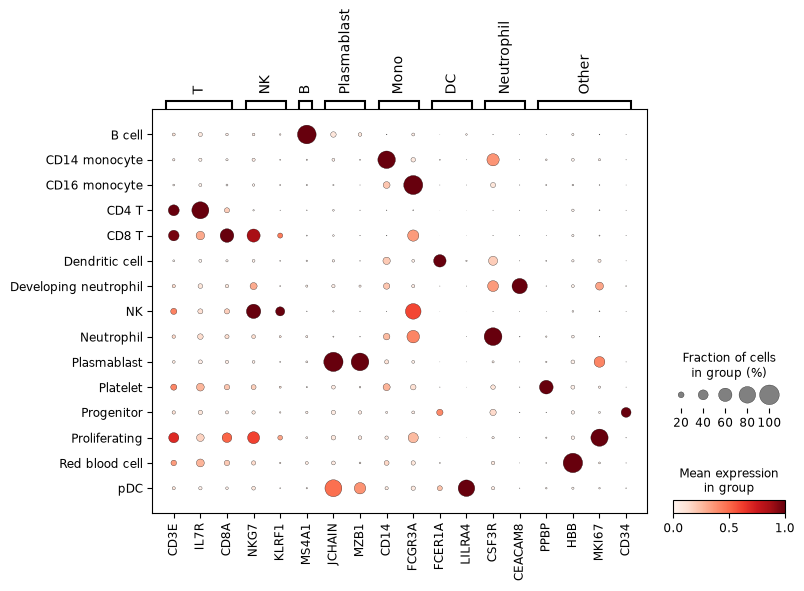

In [11]:
label = adata.obs["celltypist"].astype(str)
mixed = adata.obs["cell_type"] == "NK / CD8 T"

adata.obs["cell_type"] = adata.obs["cell_type"].astype(str)
adata.obs.loc[mixed & label.str.contains("NK"), "cell_type"] = "NK"
adata.obs.loc[mixed & label.str.contains("helper"), "cell_type"] = "CD4 T"
adata.obs.loc[mixed & ~label.str.contains("NK|helper"), "cell_type"] = "CD8 T"
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")
display(adata.obs["cell_type"].value_counts().rename_axis("cell type").to_frame("cells"))

markers = {
    "T": ["CD3E", "IL7R", "CD8A"],
    "NK": ["NKG7", "KLRF1"],
    "B": ["MS4A1"],
    "Plasmablast": ["JCHAIN", "MZB1"],
    "Mono": ["CD14", "FCGR3A"],
    "DC": ["FCER1A", "LILRA4"],
    "Neutrophil": ["CSF3R", "CEACAM8"],
    "Other": ["PPBP", "HBB", "MKI67", "CD34"],
}
sc.pl.dotplot(adata, markers, groupby="cell_type", gene_symbols="gene_name", standard_scale="var")

The dot plot shows a clear diagonal, with each cell type expressing its own markers. CD8 T cells have CD3E and CD8A, NK cells have KLRF1 without CD3E, and both have NKG7, which is shared by cytotoxic cells. pDCs show some JCHAIN as well as LILRA4, which is consistent with reports of JCHAIN in pDCs. MKI67 appears in the dividing cells and also in plasmablasts and developing neutrophils, both of which divide. Platelets show faint T-cell genes, possibly from platelets attached to T cells.

## 7. Save

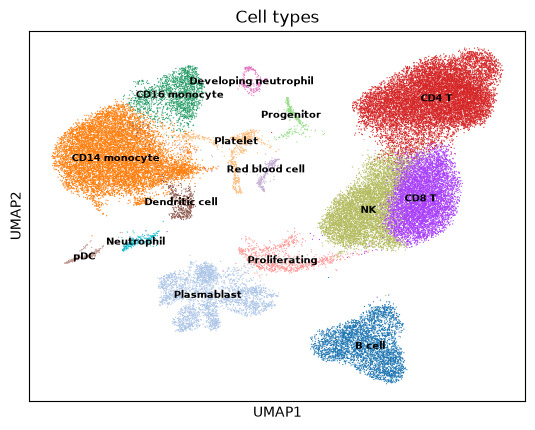

cell_type,B cell,CD14 monocyte,CD16 monocyte,CD4 T,CD8 T,Dendritic cell,Developing neutrophil,NK,Neutrophil,Plasmablast,Platelet,Progenitor,Proliferating,Red blood cell,pDC
sample,,,,,,,,,,,,,,,
HIP002,162,674,157,287,253,33,4,358,22,6,14,19,14,17,26
HIP015,295,316,81,596,546,42,1,297,24,4,25,5,23,14,29
HIP023,289,213,37,1905,538,25,0,389,14,11,8,15,25,12,14
HIP043,512,162,206,937,1533,33,0,1916,2,46,9,13,65,4,27
HIP044,440,459,392,1812,296,59,0,555,3,32,16,23,39,10,23
HIP045,170,215,66,908,453,32,5,303,3,11,2,13,14,47,16
covid_555_1,128,1454,136,244,419,19,8,368,27,192,83,18,43,24,18
covid_555_2,336,1805,148,702,703,16,119,500,26,534,48,11,29,12,16
covid_556,346,216,4,556,195,4,1,210,5,121,17,1,34,8,0


In [12]:
sc.pl.umap(adata, color="cell_type", legend_loc="on data", legend_fontsize=7, size=3, title="Cell types")

os.makedirs(f"{RESULTS}/annotation", exist_ok=True)
adata.write_h5ad(f"{RESULTS}/annotation/annotated.h5ad")

counts = pd.crosstab(adata.obs["sample"], adata.obs["cell_type"])
counts.to_csv(f"{RESULTS}/annotation/cell_counts_per_sample.csv")
counts

## Summary

46,019 cells in 15 cell types, after removing 412 artifact cells (cluster 11 and similar cells elsewhere). Marker genes, CellTypist and the dot plot agree for most types; CellTypist mislabels platelets and both neutrophil groups, so those keep their marker-based names. The per-sample counts already suggest large differences between COVID and healthy samples, such as plasmablasts, which are tested per donor in the next notebook.

The pipeline (`bin/annotate.py`) runs these steps in a container on Linux, where Leiden numbers the clusters differently, so `assets/cluster_labels.csv` is keyed to the container's clusters and each label is checked against its marker gene. The NK / CD8 T split there uses per-cell marker scores (T: CD3D, CD3E, CD3G, CD8A, CD8B; NK: KLRF1, NCAM1, KLRD1, TYROBP, FCER1G), smoothed over each cell's neighbors, instead of CellTypist's majority vote, which moved about 2,700 boundary cells between NK and CD8 T across platforms. Final counts come from the pipeline and differ slightly from this notebook (46,050 cells; CD8 T 6,711, NK 6,393).